# Bulk RNA-seq part 2: differential expression and biological interpretation

**Case study: Can the transcription factors FOXA1 and HNF4A activate liver genes in a blood cell line?**

Hansen JL, Loell KJ, Cohen BA. *A test of the pioneer factor hypothesis using ectopic liver gene activation.* eLife (2022) 11:e73358. https://elifesciences.org/articles/73358

K562 cells (a blood cell line) with doxycycline inducible expression of FOXA1, HNF4A or both FOXA1 and HNF4A. For each line we have 3 uninduced and 3 induced (0.5 µg/ml doxycycline, 24 hours) samples.

**Research questions:**

1. Which genes are activated upon expression of FOXA1, HNF4A or both?
2. Are these genes liver (or intestine) specific?
3. Do FOXA1 and HNF4A activate the same genes or different genes?

Here we will use DESeq2 to perform differential gene expression analysis. DESeq2 has a nice tutorial that can be found [here](http://bioconductor.org/packages/devel/bioc/vignettes/DESeq2/inst/doc/DESeq2.html).

**Note**:

All R packages can be installed in a single mamba environment. This environment also contains `r-irkernel`, which allows us to run R code in a Jupyter notebook (and `jupyter_client`, which is needed to register the kernel).

    mamba create -n rnaseq_r -c conda-forge -c bioconda r-base=4.4 bioconductor-deseq2 bioconductor-apeglm bioconductor-clusterprofiler bioconductor-org.hs.eg.db bioconductor-enrichplot r-ggplot2 r-ggrepel r-pheatmap r-dplyr r-tidyr r-irkernel r-upsetr jupyter_client

To use this environment in Jupyter we have to register it as a *kernel*. Run the following commands in a terminal (not in this notebook):

```
mamba activate rnaseq_r
R -e 'IRkernel::installspec(name = "ir-foxa1_hnf4a", displayname = "R (FoxA1/Hnf4a RNA-seq)")'
jupyter kernelspec list   # the kernel ir-foxa1_hnf4a should be listed
```

Next, (re)start Jupyter and select the kernel "R (FoxA1/Hnf4a RNA-seq)" (Kernel > Change Kernel).

## Step 0. set up working directory

We will use the count matrix generated in the previous notebook, which is stored in the `data` folder.

In [1]:
setwd("data")
options(repr.plot.width = 7, repr.plot.height = 5) # size of the plots in the notebook

In [2]:
suppressPackageStartupMessages({
    library(DESeq2)
    library(ggplot2)
    library(ggrepel)
    library(dplyr)
    library(pheatmap)
})

## Step 1. Load data

The starting point of a DESeq2 analysis is a count matrix K with one row for each gene i and one column for each sample j. The matrix entries $K_{ij}$ indicate the number of sequencing reads (here read pairs) that have been unambiguously mapped to a gene in a sample. Let's load the count matrix we generated in the previous notebook.

In [3]:
cts <- as.matrix(read.csv("counts/foxa1_hnf4a.counts.formatted", sep="\t", row.names = "Geneid"))

In [4]:
head(cts, 5)

,FOXA1HNF4A_I1,FOXA1HNF4A_I2,FOXA1HNF4A_I3,FOXA1HNF4A_U1,FOXA1HNF4A_U2,FOXA1HNF4A_U3,FOXA1_I1,FOXA1_I2,FOXA1_I3,FOXA1_U1,FOXA1_U2,FOXA1_U3,HNF4A_I1,HNF4A_I2,HNF4A_I3,HNF4A_U1,HNF4A_U2,HNF4A_U3
DDX11L2,487,452,392,265,218,178,248,221,188,143,144,110,243,296,156,170,199,155
DDX11L1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
WASH7P,553,488,562,425,462,327,326,296,263,188,256,195,154,218,187,209,245,202
MIR6859-1,47,58,57,36,49,19,44,30,31,25,39,16,13,19,18,23,25,19
MIR1302-2HG,5,4,2,2,1,0,0,1,6,2,0,2,2,0,0,1,0,0


In [5]:
dim(cts)

[1] 61510    18

We have 18 samples and more than 60,000 genes (this includes protein coding genes, but also non-coding RNAs, pseudogenes, ...).

Next we will generate a dataframe containing metadata on our samples. We can extract this information from the sample names (e.g. `FOXA1HNF4A_I2` is the FOXA1-HNF4A line, induced, replicate 2).

In [6]:
coldata <- data.frame(
    row.names = colnames(cts),
    line      = sub("_.*", "", colnames(cts)),                                       # everything before the "_"
    condition = ifelse(grepl("_U", colnames(cts)), "uninduced", "induced"),          # U = uninduced, I = induced
    replicate = sub(".*_[UI]", "rep", colnames(cts))                                 # the number after U or I
)
coldata$line      <- factor(coldata$line, levels = c("FOXA1", "HNF4A", "FOXA1HNF4A"))
coldata$condition <- factor(coldata$condition, levels = c("uninduced", "induced"))  # uninduced is our baseline
coldata$group     <- factor(paste(coldata$line, coldata$condition, sep = "_"))

In [7]:
coldata

,line,condition,replicate,group
,<fct>,<fct>,<chr>,<fct>
FOXA1HNF4A_I1,FOXA1HNF4A,induced,rep1,FOXA1HNF4A_induced
FOXA1HNF4A_I2,FOXA1HNF4A,induced,rep2,FOXA1HNF4A_induced
FOXA1HNF4A_I3,FOXA1HNF4A,induced,rep3,FOXA1HNF4A_induced
FOXA1HNF4A_U1,FOXA1HNF4A,uninduced,rep1,FOXA1HNF4A_uninduced
FOXA1HNF4A_U2,FOXA1HNF4A,uninduced,rep2,FOXA1HNF4A_uninduced
FOXA1HNF4A_U3,FOXA1HNF4A,uninduced,rep3,FOXA1HNF4A_uninduced
FOXA1_I1,FOXA1,induced,rep1,FOXA1_induced
FOXA1_I2,FOXA1,induced,rep2,FOXA1_induced
FOXA1_I3,FOXA1,induced,rep3,FOXA1_induced


**It's critical that the columns of the count matrix and the rows of the coldata are in the same order**. This is the case here.

In [8]:
all(rownames(coldata) == colnames(cts))

[1] TRUE

## Step 2. Exploratory analysis: how similar are the samples?

Before testing for differential expression it is a good idea to check how similar the samples are to each other. We expect that replicates are very similar, and that induced and uninduced samples are different.

First we construct a DESeqDataSet containing all 18 samples. For this we need:
- the count matrix (cts)
- the metadata (coldata)
- the design, this specifies which variables to use to perform differential gene expression testing. Here we use the `group` column (the combination of cell line and condition).

In [9]:
dds_all <- DESeqDataSetFromMatrix(countData = cts,
                                  colData = coldata,
                                  design = ~ group)
dds_all

class: DESeqDataSet 
dim: 61510 18 
metadata(1): version
assays(1): counts
rownames(61510): DDX11L2 DDX11L1 ... ENSG00000278817 ENSG00000277196
rowData names(0):
colnames(18): FOXA1HNF4A_I1 FOXA1HNF4A_I2 ... HNF4A_U2 HNF4A_U3
colData names(4): line condition replicate group

We will perform some prefiltering to only keep genes that have a count of at least 10 for a minimum of 3 samples (the size of our smallest group).

In [10]:
smallestGroupSize <- 3
keep <- rowSums(counts(dds_all) >= 10) >= smallestGroupSize
dds_all <- dds_all[keep,]
dds_all

class: DESeqDataSet 
dim: 19680 18 
metadata(1): version
assays(1): counts
rownames(19680): DDX11L2 WASH7P ... ENSG00000275869 ENSG00000278817
rowData names(0):
colnames(18): FOXA1HNF4A_I1 FOXA1HNF4A_I2 ... HNF4A_U2 HNF4A_U3
colData names(4): line condition replicate group

Raw counts are not suitable to compare samples:

- samples are sequenced to a different depth (the FOXA1-HNF4A samples have twice as many reads!)
- the variance of counts depends on the mean: highly expressed genes have a much larger variance than lowly expressed genes. If we would compute distances on raw counts, they would be dominated by a few highly expressed genes.

DESeq2 provides the *variance stabilizing transformation* (`vst`). This normalizes the counts for sequencing depth and transforms them to a log2-like scale where the variance is (approximately) independent of the mean.

In [11]:
vsd_all <- vst(dds_all, blind = TRUE)
head(assay(vsd_all), 3)

,FOXA1HNF4A_I1,FOXA1HNF4A_I2,FOXA1HNF4A_I3,FOXA1HNF4A_U1,FOXA1HNF4A_U2,FOXA1HNF4A_U3,FOXA1_I1,FOXA1_I2,FOXA1_I3,FOXA1_U1,FOXA1_U2,FOXA1_U3,HNF4A_I1,HNF4A_I2,HNF4A_I3,HNF4A_U1,HNF4A_U2,HNF4A_U3
DDX11L2,8.131604,8.096979,7.934569,7.521028,7.300346,7.287596,8.148025,8.345700,8.120579,7.937044,7.658882,7.650269,8.367048,8.458133,8.087228,7.901621,8.097909,7.976653
WASH7P,8.297638,8.196619,8.403479,8.118496,8.244586,8.044968,8.507902,8.735085,8.562693,8.291841,8.399366,8.386471,7.777759,8.057493,8.323852,8.167870,8.369910,8.320968
MIR6859-1,5.624914,5.835472,5.834510,5.518032,5.770598,5.221693,6.162987,6.053810,6.074470,5.997750,6.200533,5.650186,5.327986,5.504288,5.740406,5.752530,5.818101,5.719768


### Principal component analysis (PCA)

A PCA summarizes the expression of thousands of genes into a few *principal components* (PCs). The first PC captures the most variation between the samples, the second PC captures the most variation that is not captured by the first PC, etc. Samples that are close to each other in a PCA plot have a similar expression profile.

DESeq2 has a function `plotPCA` which by default uses the 500 most variable genes.

using ntop=500 top features by variance



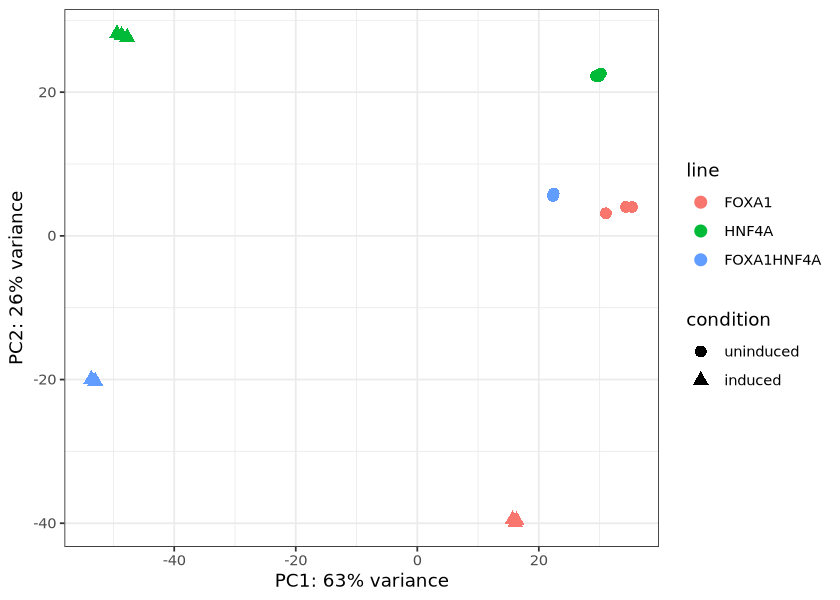

In [12]:
pcaData <- plotPCA(vsd_all, intgroup = c("line", "condition"), returnData = TRUE)
percentVar <- round(100 * attr(pcaData, "percentVar"))
ggplot(pcaData, aes(x = PC1, y = PC2, color = line, shape = condition)) +
    geom_point(size = 3) +
    xlab(paste0("PC1: ", percentVar[1], "% variance")) +
    ylab(paste0("PC2: ", percentVar[2], "% variance")) +
    theme_bw()

Each dot is a sample. Note that:

- Replicates are very close to each other (the three dots of each group almost overlap), this means that the replicates are very reproducible.
- The uninduced samples of the three lines are close to each other (right side of the plot): without doxycycline the three lines are very similar, as expected (they are all K562 cells).
- The first principal component (PC1, 63% of the variance) separates the induced samples of the HNF4A and FOXA1-HNF4A lines from the uninduced samples. The induced FOXA1 samples are much closer to the uninduced samples on PC1.
- The second principal component (PC2) separates the induced samples of the three lines from each other: FOXA1, HNF4A and FOXA1-HNF4A each induce a different expression program.

**Question**: Based on this plot, which transcription factor has the largest effect on gene expression, FOXA1 or HNF4A?

### Sample-to-sample distances

Another way to look at this is by calculating the (euclidean) distance between all pairs of samples and plotting these as a heatmap.

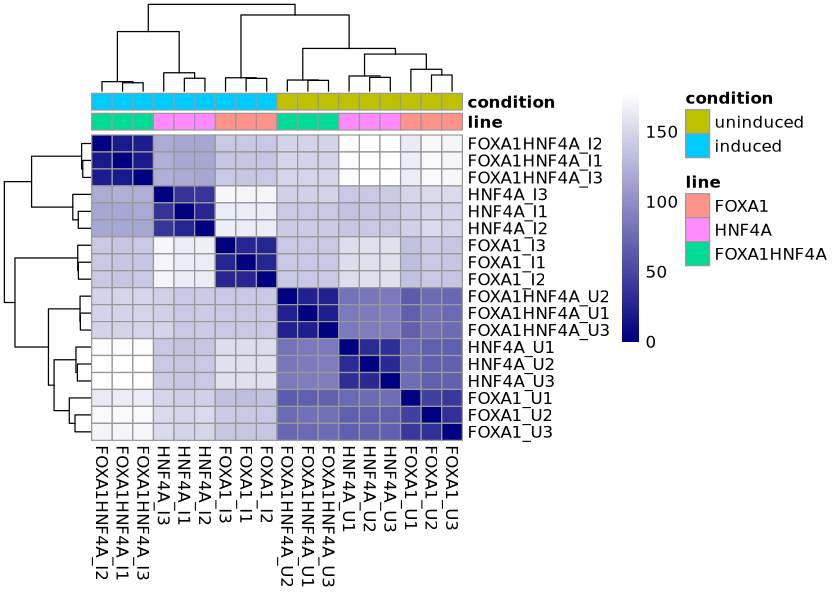

In [13]:
sampleDists <- dist(t(assay(vsd_all)))
pheatmap(as.matrix(sampleDists),
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         color = colorRampPalette(c("navy", "white"))(100),
         annotation_col = coldata[, c("line", "condition")])

The samples first cluster by condition (induced vs uninduced) and then by cell line. Again we see that replicates are very similar (dark blue squares along the diagonal).

Because the three cell lines are separate clonal lines with a different baseline expression, we will compare induced vs uninduced samples **within each cell line**. We will start with the FOXA1-HNF4A line (Figure 1 of the paper) and later repeat the analysis for the FOXA1 and HNF4A lines (Figure 2 of the paper).

## Step 3. Model read counts and performing differential expression analysis

Let's make a DESeqDataSet containing only the FOXA1-HNF4A samples. Our design is now `~ condition`, as we want to test for differential expression between induced and uninduced.

In [14]:
samples_fh <- rownames(coldata)[coldata$line == "FOXA1HNF4A"]
dds <- DESeqDataSetFromMatrix(countData = cts[, samples_fh],
                              colData = coldata[samples_fh, ],
                              design = ~ condition)
dds$condition <- factor(dds$condition, levels = c("uninduced","induced")) # uninduced is our baseline
keep <- rowSums(counts(dds) >= 10) >= smallestGroupSize
dds <- dds[keep,]
dds

class: DESeqDataSet 
dim: 19005 6 
metadata(1): version
assays(1): counts
rownames(19005): DDX11L2 WASH7P ... ENSG00000275869 ENSG00000278817
rowData names(0):
colnames(6): FOXA1HNF4A_I1 FOXA1HNF4A_I2 ... FOXA1HNF4A_U2
  FOXA1HNF4A_U3
colData names(4): line condition replicate group

Given the count matrix: $K_{ij}$ with one row for each gene $i$ and one column for each sample $j$

Read counts $K_{ij}$ are modeled as a negative binomial distribution (a.k.a. gamma-Poisson distribution) with a fitted mean $\mu_{ij}$ and gene specific dispersion $\alpha_{i}$.

<p style="text-align: center;">$K_{ij} \sim \text{NB}(\mu_{ij}, \alpha_{i})$</p>

For illustrative purposes, the distribution of the expression of genes in sample FOXA1HNF4A_U1 is shown.

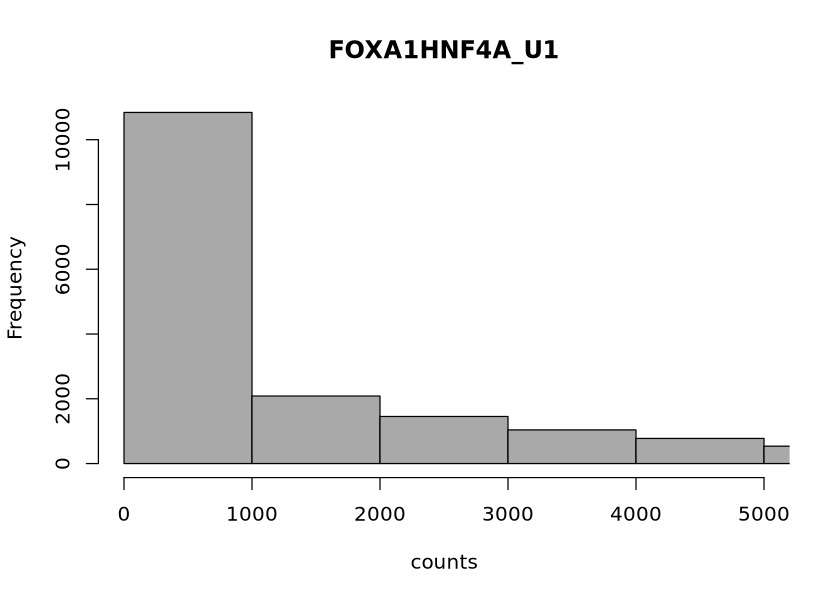

In [15]:
hist(counts(dds)[, 'FOXA1HNF4A_U1'], breaks = 1000, xlim = c(0, 5000), col = "darkgray", main = "FOXA1HNF4A_U1", xlab = "counts")

Most genes have a low count, while a few genes have a very high count.

The fitted mean $\mu_{ij}$ is composed of sample-specific size factor $s_j$ and a parameter $q_{ij}$, proportional to the concentration of cDNA fragments from the gene $i$ in sample $j$.

<p style="text-align: center;">$\mu_{ij}=s_j \cdot q_{ij}$</p>

The parameter $s_j$, which is the same for all genes in a sample, accounts for differences in sequencing depths between two samples. It can also be advantageous to calculate a gene-specific normalization factor $s_{ij}$. This gene- and sample-specific normalization factor accounts for further sources of technical bias such as differing dependence on GC content, gene length, ...

In this case the formula looks like this:

<p style="text-align: center;">$\mu_{ij}=s_{ij} \cdot q_{ij}$</p>

Finally generalized linear models (GLMs) are used to fit for each gene as follows:

<p style="text-align: center;">$\log_2{q_{ij}} = \sum_r{x_{jr} \cdot \beta_{ir} }$</p>

With $x_{jr}$ a design matrix for $r$ conditions indicating whether sample $j$ belongs to each condition $r$ or not.

In this case we have only a single condition (uninduced vs induced) and thus the formula simplifies to:

<p style="text-align: center;">$\log_2{q_{ij}} = \beta_{i0} + x_{j} \cdot \beta_{i} $</p>

with $x_j = 1$ for induced samples and $x_j = 0$ for uninduced samples. $\beta_{i0}$ is the (log2) expression in uninduced samples and $\beta_{i}$ gives the log2 fold change for gene $i$.

The variability between replicates is modeled using the dispersion parameter $\alpha_{i}$. It defines the relationship between the variance of the observed count and its mean value (how far do we expect the observed count will be from the mean value).

<p style="text-align: center;">$\text{Var}(K_{ij}) = E[(K_{ij} - \mu_{ij})^2] = \mu_{ij} + \alpha_i \cdot \mu_{ij}^2$</p>

Accurate estimation of this dispersion parameter $\alpha_i$ is critical for statistical testing of differential expression. For studies with a small sample size this parameter is difficult to estimate. DESeq2 solves this issue by assuming that genes with similar average expression values will have a similar dispersion.

Let's plot the mean vs the variance of the counts of the uninduced samples.

Warning message in scale_x_continuous(trans = "log10"):
“log-10 transformation introduced infinite values.”


Warning message in scale_y_continuous(trans = "log10"):
“log-10 transformation introduced infinite values.”


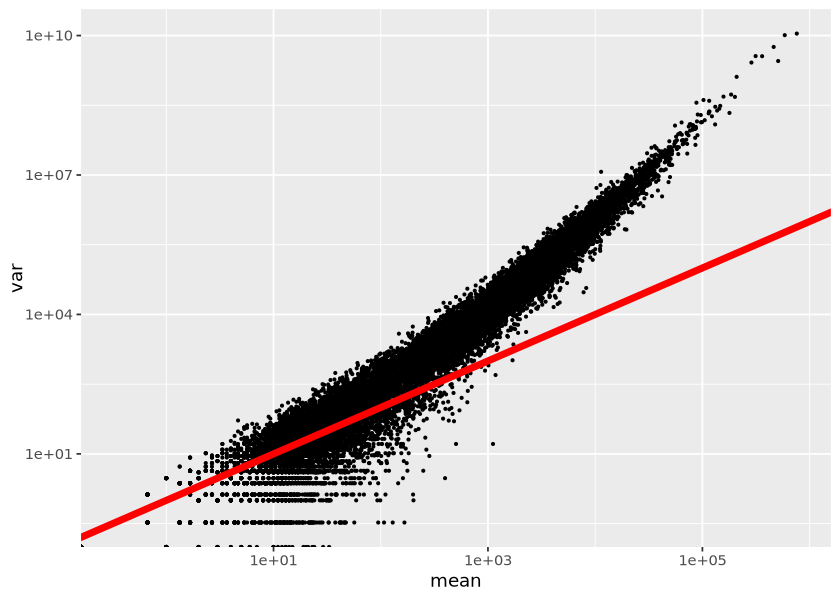

In [16]:
cts_u <- counts(dds)[, dds$condition == "uninduced"]
data <- data.frame(
    mean = rowMeans(cts_u),
    var  = rowVars(cts_u))
ggplot(data, aes(x = mean, y = var)) +
    geom_point(size = 0.5) +
    scale_x_continuous(trans = "log10") +
    scale_y_continuous(trans = "log10") +
    geom_abline(intercept = 0, slope = 1, color = "red", linewidth = 2)

The Red line represents the case where the variance equals the mean (this would be the case if the counts followed a Poisson distribution). For highly expressed genes the variance is much larger than the mean, this is called *overdispersion*.

The **size factors** $s_{j}$ can be estimated for each sample using the function

        estimateSizeFactors

In [17]:
dds <- estimateSizeFactors(dds)

In [18]:
dds@colData

DataFrame with 6 rows and 5 columns
                    line condition   replicate                group sizeFactor
                <factor>  <factor> <character>             <factor>  <numeric>
FOXA1HNF4A_I1 FOXA1HNF4A induced          rep1 FOXA1HNF4A_induced     1.139637
FOXA1HNF4A_I2 FOXA1HNF4A induced          rep2 FOXA1HNF4A_induced     1.089986
FOXA1HNF4A_I3 FOXA1HNF4A induced          rep3 FOXA1HNF4A_induced     1.072328
FOXA1HNF4A_U1 FOXA1HNF4A uninduced        rep1 FOXA1HNF4A_uninduced   0.992447
FOXA1HNF4A_U2 FOXA1HNF4A uninduced        rep2 FOXA1HNF4A_uninduced   0.968033
FOXA1HNF4A_U3 FOXA1HNF4A uninduced        rep3 FOXA1HNF4A_uninduced   0.805377

The size factors are roughly proportional to the sequencing depth of each sample.

In [19]:
data.frame(sizeFactor = sizeFactors(dds), total_counts = colSums(counts(dds)))

,sizeFactor,total_counts
,<dbl>,<dbl>
FOXA1HNF4A_I1,1.1396374,67033791
FOXA1HNF4A_I2,1.0899864,65748134
FOXA1HNF4A_I3,1.0723279,62554204
FOXA1HNF4A_U1,0.9924466,58497473
FOXA1HNF4A_U2,0.9680326,58763989
FOXA1HNF4A_U3,0.8053767,48244392


The **dispersion** $\alpha_{i}$ can be estimated using the function

    estimateDispersions

In [20]:
dds <- estimateDispersions(dds)

gene-wise dispersion estimates



mean-dispersion relationship



final dispersion estimates



In [21]:
head(mcols(dds))

DataFrame with 6 rows and 10 columns
                 baseMean   baseVar   allZero dispGeneEst dispGeneIter
                <numeric> <numeric> <logical>   <numeric>    <numeric>
DDX11L2          320.1339  8830.541     FALSE  0.00534727            5
WASH7P           461.4267  1820.891     FALSE  0.00427805            4
MIR6859-1         43.0153   138.094     FALSE  0.04401732            4
ENSG00000238009  254.3145   626.884     FALSE  0.00000001            1
ENSG00000268903  287.4685  3056.999     FALSE  0.00391897            9
ENSG00000269981  234.8585  2859.451     FALSE  0.00000001            1
                   dispFit dispersion  dispIter dispOutlier    dispMAP
                 <numeric>  <numeric> <integer>   <logical>  <numeric>
DDX11L2         0.00599286 0.00588224         9       FALSE 0.00588224
WASH7P          0.00456056 0.00450808         9       FALSE 0.00450808
MIR6859-1       0.03612692 0.03719612         9       FALSE 0.03719612
ENSG00000238009 0.00720345 0.00599192   

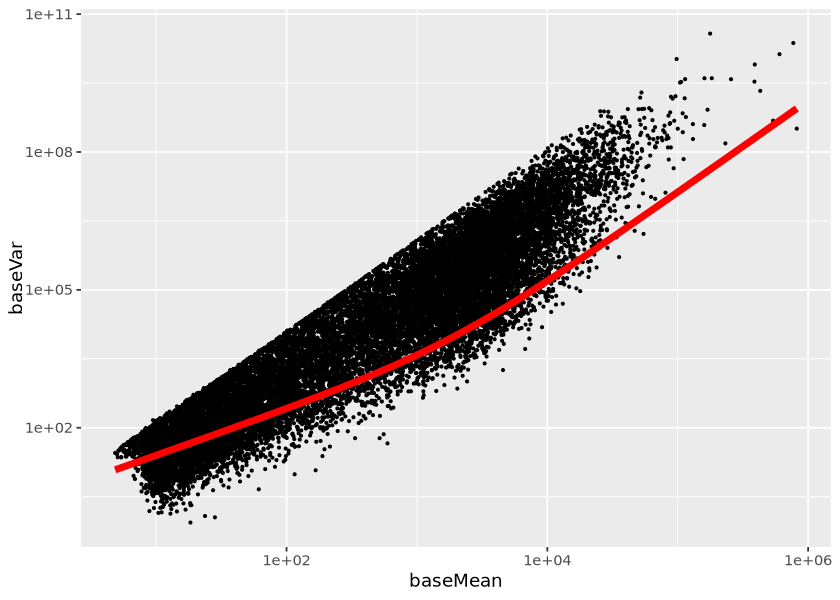

In [22]:
ggplot(as.data.frame(mcols(dds)[!mcols(dds)$allZero, ])) +
    geom_point(aes(x = baseMean, y = baseVar), size = 0.5) +
    geom_line(aes(x = baseMean, y = baseMean + dispFit * baseMean * baseMean ), color = "red", linewidth = 2) +
    scale_x_continuous(trans = "log10") +
    scale_y_continuous(trans = "log10")

As you can see the red line now fits the data much better!

DESeq2 also has a built in function to plot the dispersion estimates: the black dots are the gene-wise estimates, the red line is the fitted trend and the blue dots are the final estimates, which are *shrunk* towards the trend line.

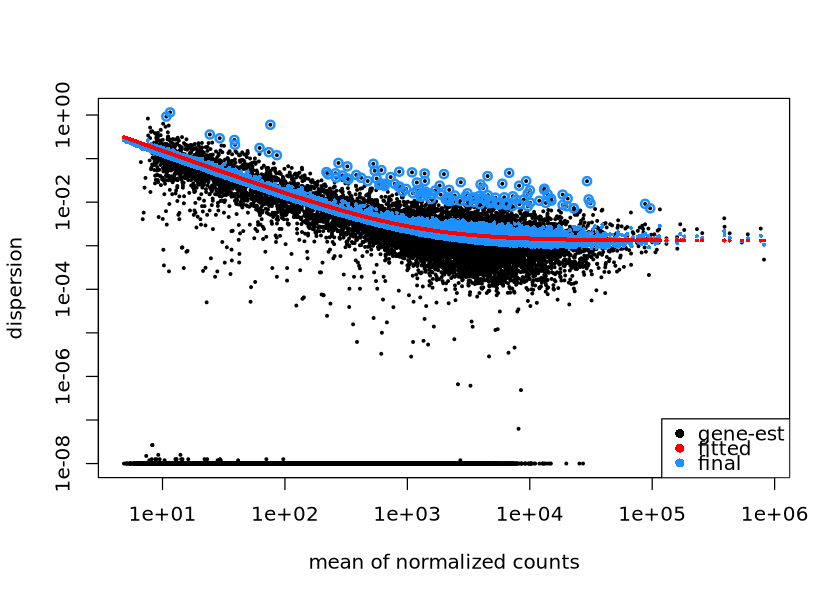

In [23]:
plotDispEsts(dds)

Finally we can **fit the GLM for each gene** to obtain $\beta_i$, the log2FC of each gene across the two conditions, using the function:

    nbinomWaldTest

In [24]:
dds <- nbinomWaldTest(dds)

The results of this can be visualized using the function

    results

In [25]:
res <- results(dds)
res

log2 fold change (MLE): condition induced vs uninduced 
Wald test p-value: condition induced vs uninduced 
DataFrame with 19005 rows and 6 columns
                 baseMean log2FoldChange     lfcSE      stat      pvalue
                <numeric>      <numeric> <numeric> <numeric>   <numeric>
DDX11L2          320.1339       0.756867 0.1135830   6.66356 2.67273e-11
WASH7P           461.4267       0.149448 0.0963437   1.55120 1.20854e-01
MIR6859-1         43.0153       0.402669 0.2911606   1.38298 1.66671e-01
ENSG00000238009  254.3145       0.216221 0.1176518   1.83780 6.60916e-02
ENSG00000268903  287.4685       0.466583 0.1161827   4.01595 5.92080e-05
...                   ...            ...       ...       ...         ...
ENSG00000273748 1233.1422       0.144615 0.0616141  2.347106 1.89199e-02
ENSG00000271254  692.0567       0.569738 0.1020040  5.585450 2.33095e-08
ENSG00000276345  422.0877      -0.811935 0.0974705 -8.330063 8.07995e-17
ENSG00000275869   21.6936       0.222374 0.4002891

- baseMean: the average of the normalized counts over all samples
- log2FoldChange: the log2 fold change (induced vs uninduced, see the header of the output)
- lfcSE: the standard error of the log2 fold change
- stat: the Wald statistic (log2FoldChange / lfcSE)
- pvalue: the p-value of the Wald test
- padj: the p-value corrected for multiple testing (Benjamini-Hochberg). We test more than 15,000 genes, so by chance alone 5% of them (> 750 genes!) would have a p-value < 0.05.

The three functions above:

    estimateSizeFactors
    estimateDispersions
    nbinomWaldTest

can be run in one go using the wrapper function:

    DESeq

In [26]:
dds <- DESeq(dds)
res <- results(dds)
res

using pre-existing size factors



estimating dispersions



found already estimated dispersions, replacing these



gene-wise dispersion estimates



mean-dispersion relationship



final dispersion estimates



fitting model and testing



log2 fold change (MLE): condition induced vs uninduced 
Wald test p-value: condition induced vs uninduced 
DataFrame with 19005 rows and 6 columns
                 baseMean log2FoldChange     lfcSE      stat      pvalue
                <numeric>      <numeric> <numeric> <numeric>   <numeric>
DDX11L2          320.1339       0.756867 0.1135830   6.66356 2.67273e-11
WASH7P           461.4267       0.149448 0.0963437   1.55120 1.20854e-01
MIR6859-1         43.0153       0.402669 0.2911606   1.38298 1.66671e-01
ENSG00000238009  254.3145       0.216221 0.1176518   1.83780 6.60916e-02
ENSG00000268903  287.4685       0.466583 0.1161827   4.01595 5.92080e-05
...                   ...            ...       ...       ...         ...
ENSG00000273748 1233.1422       0.144615 0.0616141  2.347106 1.89199e-02
ENSG00000271254  692.0567       0.569738 0.1020040  5.585450 2.33095e-08
ENSG00000276345  422.0877      -0.811935 0.0974705 -8.330063 8.07995e-17
ENSG00000275869   21.6936       0.222374 0.4002891

In [27]:
summary(res, alpha = 0.05)


out of 19005 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 7533, 40%
LFC < 0 (down)     : 7127, 38%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 5)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



Genes with a low read count have a strong variance of the log2FoldChange (see plot below). Because of this, weakly expressed genes can seem to have strong differences between two conditions. However, this is not due to a real difference but due to noise in the measurements. This will cause issues if we want to rank genes based on their log2fold change values.

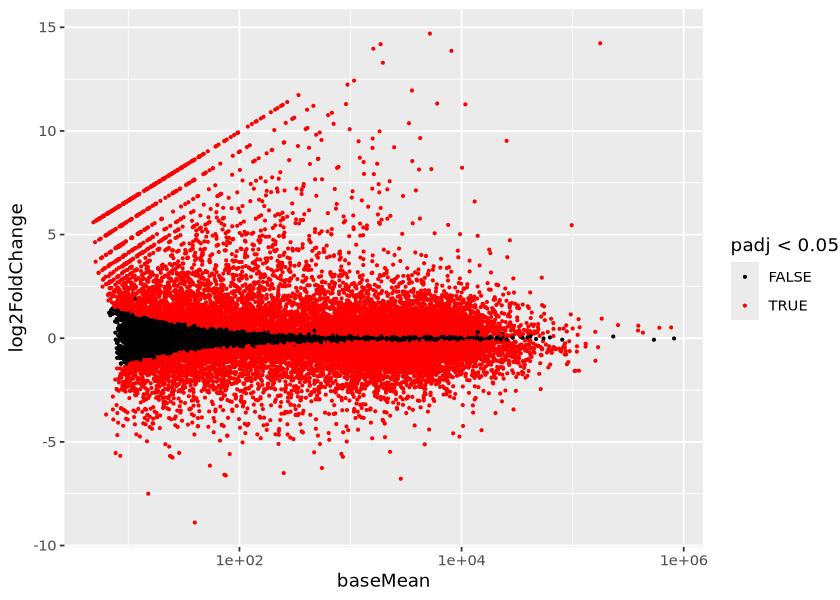

In [28]:
ggplot(as.data.frame(res), aes(x = baseMean, y = log2FoldChange)) +
    geom_point(aes(colour = padj < 0.05), size = 0.5) +
    scale_x_continuous(trans = "log10") +
    scale_color_manual(name = "padj < 0.05", values = setNames(c("red", "black"), c(T, F)))

As you can see genes with a low mean (left of the plot) have a big variance of the log2foldchange. This can also be seen by looking at the standard error of the log2foldchange vs the mean

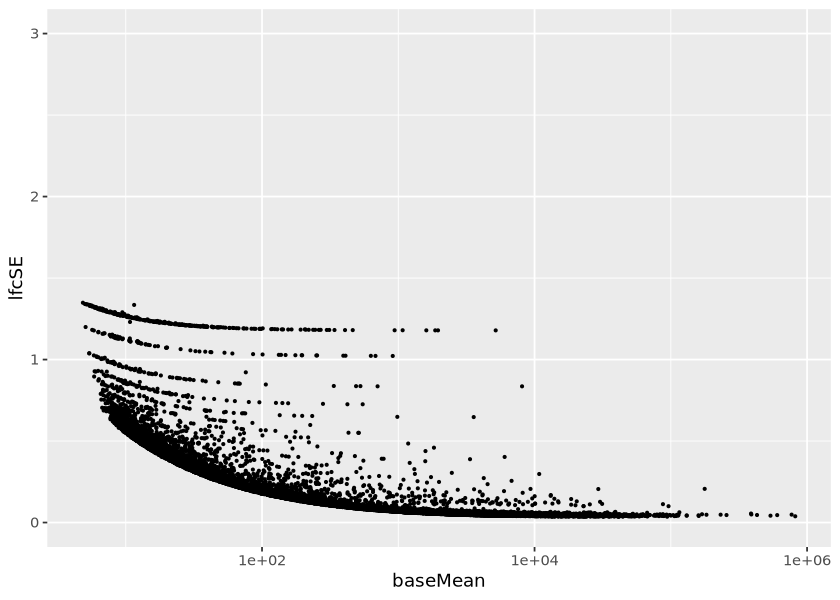

In [29]:
ggplot(as.data.frame(res), aes(x = baseMean, y = lfcSE)) +
    geom_point(size = 0.5) +
    scale_x_continuous(trans = "log10") +
    ylim(0, 3)

To account for this DESeq2 has a function to *shrink* Log2FoldChange towards zero in such a manner that the shrinkage is stronger when the available information for a gene is low (i.e. low number of counts, or dispersion is high).

The function for this is called

    lfcShrink

it takes the `dds` object as input together with the coefficient we want to shrink

In [30]:
resultsNames(dds)

[1] "Intercept"                      "condition_induced_vs_uninduced"

We want to shrink the coefficient `condition_induced_vs_uninduced` as this stores our Log2FoldChange values.

In [31]:
resLFC <- lfcShrink(dds, coef="condition_induced_vs_uninduced", type = "apeglm")

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



In [32]:
resLFC

log2 fold change (MAP): condition induced vs uninduced 
Wald test p-value: condition induced vs uninduced 
DataFrame with 19005 rows and 5 columns
                 baseMean log2FoldChange     lfcSE      pvalue        padj
                <numeric>      <numeric> <numeric>   <numeric>   <numeric>
DDX11L2          320.1339       0.749668 0.1132045 2.67273e-11 6.10374e-11
WASH7P           461.4267       0.148236 0.0959074 1.20854e-01 1.47166e-01
MIR6859-1         43.0153       0.374669 0.2814899 1.66671e-01 1.98794e-01
ENSG00000238009  254.3145       0.213563 0.1169682 6.60916e-02 8.34266e-02
ENSG00000268903  287.4685       0.461254 0.1155692 5.92080e-05 9.85590e-05
...                   ...            ...       ...         ...         ...
ENSG00000273748 1233.1422       0.144138 0.0615059 1.89199e-02 2.54061e-02
ENSG00000271254  692.0567       0.564893 0.1016724 2.33095e-08 4.72985e-08
ENSG00000276345  422.0877      -0.806241 0.0972858 8.07995e-17 2.18839e-16
ENSG00000275869   21.6936   

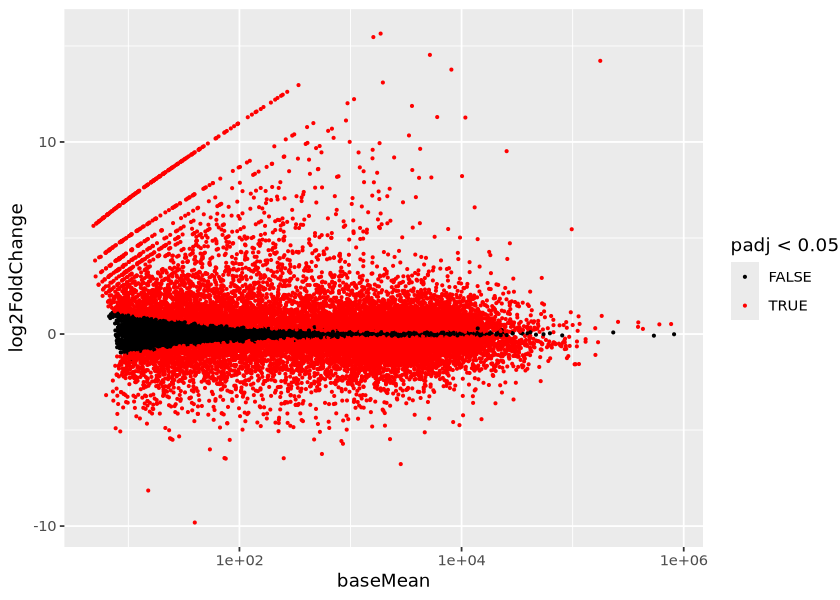

In [33]:
ggplot(as.data.frame(resLFC), aes(x = baseMean, y = log2FoldChange)) +
    geom_point(aes(colour = padj < 0.05), size = 0.5) +
    scale_x_continuous(trans = "log10") +
    scale_color_manual(name = "padj < 0.05", values = setNames(c("red", "black"), c(T, F)))

As you can see, now the effect of the mean on the variance of the Log2FoldChange is much smaller. Again we can also visualize this by plotting the standard error.

Warning message:
“Removed 13 rows containing missing values or values outside the scale range
(`geom_point()`).”


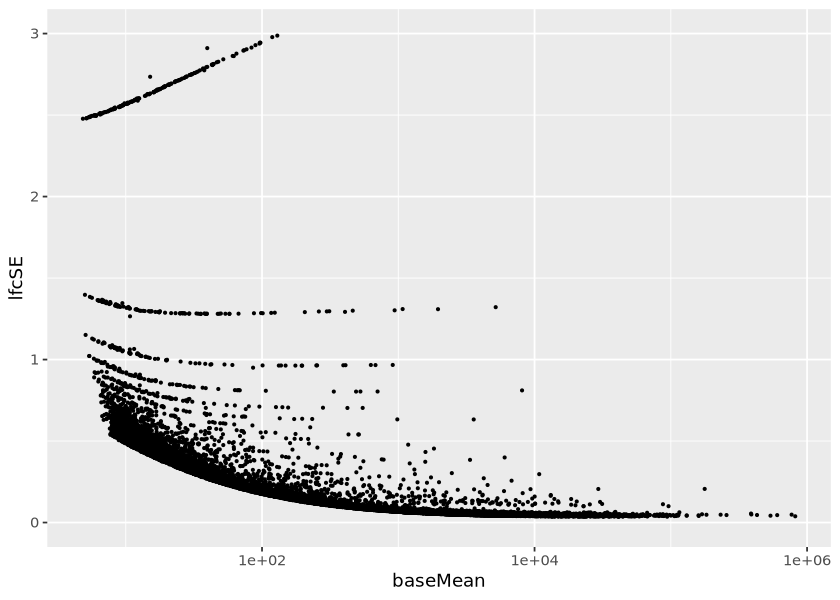

In [34]:
ggplot(as.data.frame(resLFC), aes(x = baseMean, y = lfcSE)) +
    geom_point(size = 0.5) +
    scale_x_continuous(trans = "log10") +
    ylim(0, 3)

## Step 4. Downstream analysis

### Are the transgenes induced?

Before we look at other genes, let's check whether FOXA1 and HNF4A are indeed induced upon doxycycline treatment. The function `plotCounts` plots the normalized counts of a single gene.

In [35]:
resLFC_df <- as.data.frame(resLFC)
resLFC_df[c("FOXA1", "HNF4A"), ]

,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOXA1,77.05687,-2.220851,0.2298799,9.370055e-23,2.951241e-22
HNF4A,25442.84447,9.521438,0.1113887,0.000000e+00,0.000000e+00


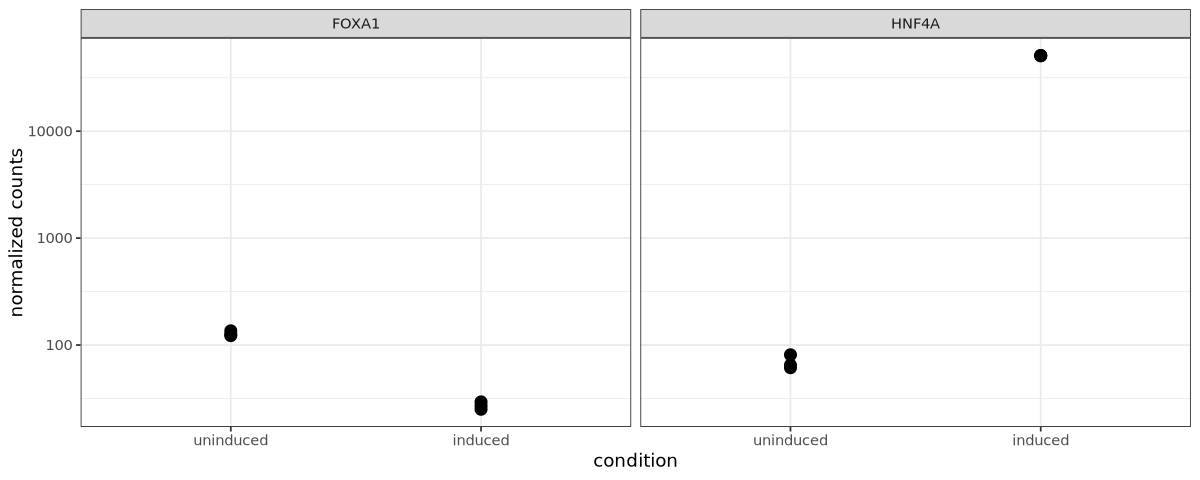

In [36]:
options(repr.plot.width = 10, repr.plot.height = 4)
d <- rbind(
    cbind(plotCounts(dds, gene = "FOXA1", intgroup = "condition", returnData = TRUE), gene = "FOXA1"),
    cbind(plotCounts(dds, gene = "HNF4A", intgroup = "condition", returnData = TRUE), gene = "HNF4A"))
ggplot(d, aes(x = condition, y = count)) +
    geom_point(size = 3) +
    scale_y_log10() +
    facet_wrap(~ gene) +
    ylab("normalized counts") +
    theme_bw()
options(repr.plot.width = 7, repr.plot.height = 5)

HNF4A is very strongly induced (log2 fold change of 9.5, i.e. ~ 700 fold). As we have seen in the previous notebook, we can't measure the expression of the FOXA1 transgene because it is codon optimized: the reads coming from the transgene do not map to the *FOXA1* gene. The reads that map to *FOXA1* come from the endogenous gene, which is even downregulated upon induction.

### Getting a list of up- or downregulated genes
To manipulate dataframes we use the package dplyr.

Let's define some thresholds

In [37]:
log2FC_thr = 1
pad_thr = 0.05

In [38]:
upregulated_genes <- row.names(resLFC_df %>%
    filter(log2FoldChange > log2FC_thr, padj < pad_thr))
downregulated_genes <- row.names(resLFC_df %>%
    filter(log2FoldChange < -log2FC_thr, padj < pad_thr))
length(upregulated_genes)
length(downregulated_genes)

[1] 3713

[1] 2819

That's a lot of genes! In fact, without a log2 fold change threshold more than 75% of the genes have a padj < 0.05 (see the output of `summary(res)` above). This is because these samples are sequenced very deeply and the replicates are very similar (low dispersion), which gives us a lot of statistical power: even very small changes in expression become significant. A significant change is not necessarily a biologically relevant change. This is why we also use a threshold on the log2 fold change.

### Sorting the gene list based on log2FC values

In [39]:
resLFC_df %>%
    filter(padj < pad_thr) %>%
    arrange(desc(log2FoldChange)) %>%
    head(20)

,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CCL16,1867.0310,15.64425,3.3147607,2.421641e-33,9.417491e-33
SLC22A7,1605.9029,15.46206,3.3617126,2.253930e-32,8.644992e-32
RBP2,5185.8350,14.53472,1.3213470,1.123481e-35,4.539063e-35
APOA1,177230.4249,14.22492,0.2062130,0.000000e+00,0.000000e+00
APOB,8095.0779,13.76869,0.8106404,7.964253e-62,4.678845e-61
AGR2,1956.2350,13.09582,1.3089093,1.780246e-29,6.474088e-29
CYP8B1,340.3327,12.96197,3.1032351,3.044706e-23,9.689323e-23
AWAT1,269.4115,12.61159,3.0978618,5.572196e-22,1.726718e-21
RGN,245.4528,12.46070,3.0827251,1.693279e-21,5.189610e-21


Many of the genes with the highest log2 fold change are typical liver genes, for example the apolipoproteins APOA1, APOB and APOC3, which are made by the liver (and the intestine) and transport lipids through the blood. Also HNF1A, another liver transcription factor, is activated.

Note that for many of these genes the lfcSE (the uncertainty on the log2 fold change) is large (~3). These genes have (almost) zero counts in the uninduced samples, so the fold change is very uncertain: is it 2^12 or 2^15 fold? It doesn't really matter, the gene is clearly switched on!

### Volcano plot

A volcano plot shows the log2 fold change (x-axis) versus the significance (-log10 adjusted p-value, y-axis) of each gene.

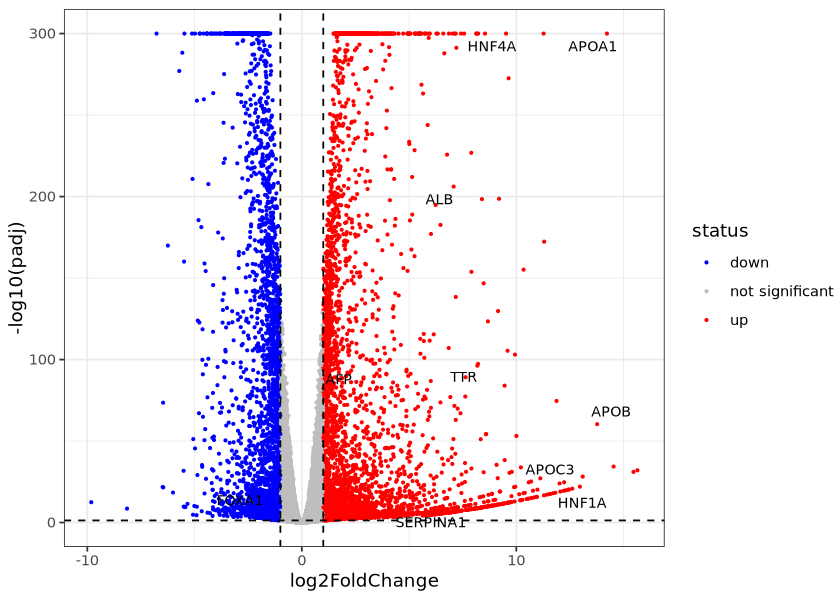

In [40]:
resLFC_df$gene <- rownames(resLFC_df)
resLFC_df$status <- "not significant"
resLFC_df$status[resLFC_df$gene %in% upregulated_genes]   <- "up"
resLFC_df$status[resLFC_df$gene %in% downregulated_genes] <- "down"
# some padj values are so small that they are rounded to 0 (-log10(0) is infinite), we set these to 1e-300
resLFC_df$padj_plot <- pmax(resLFC_df$padj, 1e-300)
genes_to_label <- c("HNF4A", "FOXA1", "ALB", "APOA1", "APOB", "APOC3", "SERPINA1", "HNF1A", "TTR", "AFP")
top_genes <- resLFC_df %>% filter(gene %in% genes_to_label)
ggplot(resLFC_df %>% filter(!is.na(padj)), aes(x = log2FoldChange, y = -log10(padj_plot), color = status)) +
    geom_point(size = 0.5) +
    geom_text_repel(data = top_genes, aes(label = gene), color = "black", size = 3, max.overlaps = 20) +
    scale_color_manual(values = c("up" = "red", "down" = "blue", "not significant" = "gray")) +
    geom_vline(xintercept = c(-log2FC_thr, log2FC_thr), linetype = "dashed") +
    geom_hline(yintercept = -log10(pad_thr), linetype = "dashed") +
    ylab("-log10(padj)") +
    theme_bw()

Many genes are strongly upregulated, including several well known liver genes (ALB, APOA1, APOB, SERPINA1, ...). Note that more genes are strongly *up* than strongly *down* regulated (the plot is asymmetric): FOXA1 and HNF4A are transcriptional activators.

### Plotting a heatmap

To plot a heatmap we use the variance stabilized counts (see above) and scale each gene (row) to have a mean of 0 and a standard deviation of 1 (`scale = "row"`). This way we can compare the pattern of genes with very different expression levels.

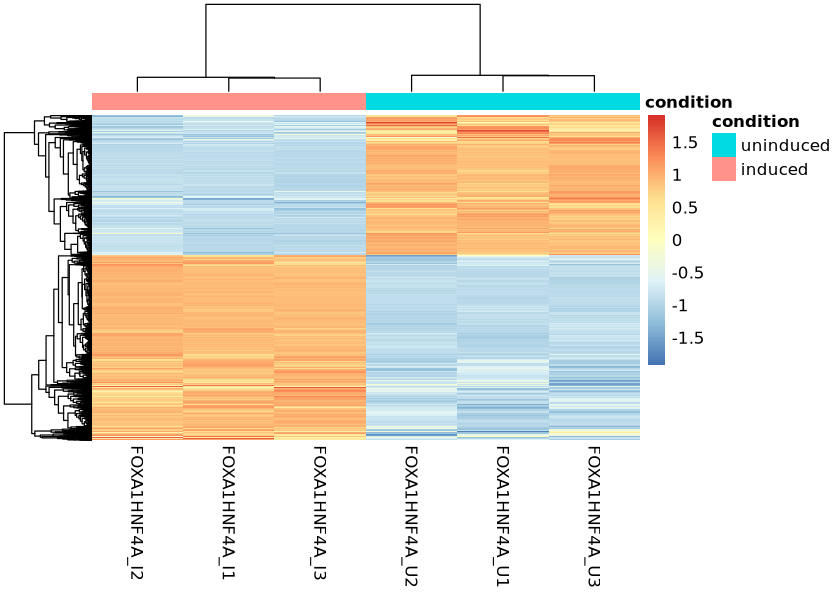

In [41]:
vsd <- vst(dds, blind = FALSE)
pheatmap(assay(vsd)[c(upregulated_genes, downregulated_genes), ],
         scale = "row", show_rownames = F,
         annotation_col = coldata[, c("condition"), drop = FALSE])

The heatmap shows the expression of all up- and downregulated genes: the replicates are very consistent.

## Step 5. Biological interpretation

### Which genes are *activated*?

We are mostly interested in genes that are silent in K562 cells and that become activated by FOXA1 and HNF4A. In the paper (see Methods) a gene was called:

- *upregulated* if it had a log2 fold change of at least 1
- *activated* if, in addition, it had fewer than 50 normalized reads in the uninduced control.

We will use the same definition, but we will also require that the change is significant (padj < 0.05).

Let's write a function that gives us the activated genes, so we can easily reuse this later for the other cell lines. Normalized counts can be obtained with `counts(dds, normalized = TRUE)`.

In [42]:
get_activated_genes <- function(dds, resLFC, log2FC_thr = 1, pad_thr = 0.05, max_uninduced = 50) {
    norm_counts <- counts(dds, normalized = TRUE)
    mean_uninduced <- rowMeans(norm_counts[, dds$condition == "uninduced"])
    df <- as.data.frame(resLFC)
    df$mean_uninduced <- mean_uninduced[rownames(df)]
    rownames(df %>% filter(log2FoldChange >= log2FC_thr, padj < pad_thr, mean_uninduced < max_uninduced))
}
activated_fh <- get_activated_genes(dds, resLFC)
length(activated_fh)

[1] 2037

More than 2000 genes are activated: these genes are (almost) silent in uninduced K562 cells, and are switched on by FOXA1 and HNF4A.

### Are the activated genes liver specific?

FOXA1 and HNF4A are important TFs in the liver (and intestine). Are the activated genes liver (or intestine) specific genes?

To answer this question we need a list of tissue specific genes. The [Human Protein Atlas](https://www.proteinatlas.org/) (HPA) measured the expression of all genes in many human tissues using RNA-seq. A gene is called *tissue enriched* if it has at least four-fold higher expression in one tissue compared to all other tissues. This is the same definition as used in the paper.

Let's download the HPA data.

In [43]:
if (!file.exists("annotation/proteinatlas.tsv")) {
    dir.create("annotation", showWarnings = FALSE)
    download.file("https://www.proteinatlas.org/download/proteinatlas.tsv.zip", "annotation/proteinatlas.tsv.zip")
    unzip("annotation/proteinatlas.tsv.zip", exdir = "annotation")
}
hpa <- read.csv("annotation/proteinatlas.tsv", sep = "\t", check.names = FALSE)
dim(hpa)

[1] 20162   119

In [44]:
hpa[hpa$Gene %in% c("ALB", "FOXA1", "ACTB"), c("Gene", "Ensembl", "RNA tissue specificity", "RNA tissue specific nTPM")]

,Gene,Ensembl,RNA tissue specificity,RNA tissue specific nTPM
,<chr>,<chr>,<chr>,<chr>
1308,ACTB,ENSG00000075624,Low tissue specificity,
6064,FOXA1,ENSG00000129514,Tissue enhanced,prostate: 70.2
10888,ALB,ENSG00000163631,Tissue enriched,liver: 198523.8


- `RNA tissue specificity`: the category of tissue specificity (Tissue enriched, Group enriched, Tissue enhanced, Low tissue specificity, Not detected)
- `RNA tissue specific nTPM`: the tissue(s) in which the gene is specifically expressed and the expression level (nTPM: normalized transcripts per million)

ALB is liver enriched, FOXA1 is higher expressed in the prostate than in other tissues (tissue enhanced) and ACTB (beta-actin) is expressed in all tissues (low tissue specificity).

Let's get the tissue enriched genes for the liver and the intestine.

In [45]:
hpa_enriched <- hpa[hpa$`RNA tissue specificity` == "Tissue enriched", ]
hpa_enriched$tissue <- sub(":.*", "", hpa_enriched$`RNA tissue specific nTPM`)  # remove the expression value
head(sort(table(hpa_enriched$tissue), decreasing = TRUE), 10)


         testis           brain           liver lymphoid tissue          skin 1 
            932             475             267             206             187 
         retina       intestine     bone marrow      epididymis        placenta 
            129             123             109              96              65 

In [46]:
liver_genes     <- hpa_enriched$Gene[hpa_enriched$tissue == "liver"]
intestine_genes <- hpa_enriched$Gene[hpa_enriched$tissue == "intestine"]
length(liver_genes)
length(intestine_genes)

[1] 267

[1] 123

The current version of the HPA has 267 liver enriched genes and 123 intestine enriched genes (the paper used an older version with 242 and 122 genes).

How many of the activated genes are liver or intestine enriched?

In [47]:
activated_fh[activated_fh %in% liver_genes]

[1] "C8A"         "HMGCS2"      "FMO5"        "APOA2"       "NR1I3"      
 [6] "SERPINC1"    "CFHR1"       "CFHR2"       "CFHR5"       "C4BPB"      
[11] "AGT"         "PLGLB2"      "PROC"        "ABCB11"      "CYP8B1"     
[16] "RTP3"        "ITIH3"       "ITIH4"       "ACOX2"       "CP"         
[21] "SLC2A2"      "AHSG"        "FETUB"       "KNG1"        "CPN2"       
[26] "BDH1"        "UGT2B10"     "GC"          "ALB"         "AFM"        
[31] "CFI"         "FGB"         "FGA"         "FGG"         "C9"         
[36] "CFB"         "SLC22A7"     "SMLR1"       "ARG1"        "SLC22A1"    
[41] "PLG"         "PON3"        "EPO"         "AKR1D1"      "FGL1"       
[46] "GLDC"        "BAAT"        "ORM1"        "ORM2"        "C8G"        
[51] "ITIH2"       "A1CF"        "CPN1"        "HPX"         "F2"         
[56] "SLC22A9"     "APOC3"       "APOA1"       "CLEC1B"      "GYS2"       
[61] "APOF"        "RDH16"       "HPD"         "F7"          "PROZ"       
[66] "ANG"         "RNASE4"      "SERPINA1"    "SLC25A47"    "CES1"       
[71] "CA5A"        "SERPINF2"    "SLC13A5"     "ASGR2"       "SHBG"       
[76] "VTN"         "CCL16"       "PGLYRP2"     "CYP2A6"      "CYP2A7"     
[81] "CYP2B6"      "APOC4-APOC2" "APOC2"       "SULT2A1"     "LBP"        
[86] "SERPIND1"    "UPB1"        "PNPLA3"

In [48]:
activated_fh[activated_fh %in% intestine_genes]

[1] "CLCA1"     "DQX1"      "MYO7B"     "ALPI"      "HHLA2"     "MUC13"    
 [7] "RBP2"      "CDHR2"     "BNIP5"     "MEP1A"     "MUC17"     "SLC26A3"  
[13] "TRPM6"     "C11orf86"  "TBX10"     "APOA4"     "GUCY2C"    "SOAT2"    
[19] "MYO1A"     "MYRFL"     "TMEM253"   "ZG16"      "SULT1A3"   "TMIGD1"   
[25] "ANKRD40CL" "ENPP7"     "LGALS4"    "CEACAM20"  "CEACAM18"  "ISX"

Is this more than expected by chance? We can test this using a **hypergeometric test**. Imagine an urn containing N balls (all genes), of which m are white (liver genes) and N - m are black (other genes). If we randomly draw k balls (the activated genes), how likely is it to draw q or more white balls?

- N: the total number of genes (our *universe*)
- m: the number of liver genes
- k: the number of activated genes
- q: the number of activated liver genes

The expected number of white balls is $k \cdot \frac{m}{N}$.

The choice of the universe is important. The HPA only contains protein coding genes, so we will use all protein coding genes in our count matrix (i.e. genes that are present in the HPA) as universe.

In [49]:
universe <- intersect(rownames(cts), hpa$Gene)
length(universe)

[1] 20024

In [50]:
hypergeometric_test <- function(activated, tissue_genes, universe) {
    activated    <- intersect(activated, universe)
    tissue_genes <- intersect(tissue_genes, universe)
    N <- length(universe)
    m <- length(tissue_genes)
    k <- length(activated)
    q <- length(intersect(activated, tissue_genes))
    data.frame(
        observed = q,
        expected = k * m / N,
        # P(X >= q) = 1 - P(X <= q - 1)
        pvalue   = phyper(q - 1, m, N - m, k, lower.tail = FALSE))
}

In [51]:
enrichment_fh <- rbind(
    cbind(tissue = "liver",     hypergeometric_test(activated_fh, liver_genes, universe)),
    cbind(tissue = "intestine", hypergeometric_test(activated_fh, intestine_genes, universe)))
enrichment_fh

tissue,observed,expected,pvalue
<chr>,<int>,<dbl>,<dbl>
liver,88,13.654015,1.948694e-47
intestine,30,6.290052,4.927267e-13


Let's plot this, similar to Figure 1B of the paper.

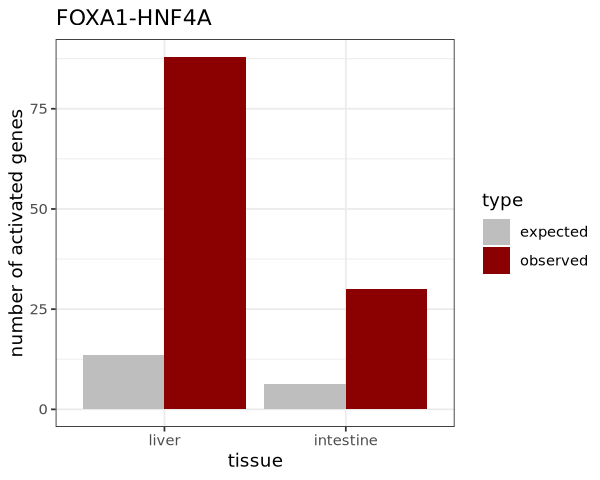

In [52]:
plot_enrichment <- function(enrichment, title) {
    d <- rbind(
        data.frame(tissue = enrichment$tissue, type = "expected", n = enrichment$expected),
        data.frame(tissue = enrichment$tissue, type = "observed", n = enrichment$observed))
    d$tissue <- factor(d$tissue, levels = c("liver", "intestine"))
    ggplot(d, aes(x = tissue, y = n, fill = type)) +
        geom_col(position = "dodge") +
        scale_fill_manual(values = c("expected" = "gray", "observed" = "darkred")) +
        ylab("number of activated genes") +
        ggtitle(title) +
        theme_bw()
}
options(repr.plot.width = 5, repr.plot.height = 4)
plot_enrichment(enrichment_fh, "FOXA1-HNF4A")

We find 88 activated liver genes, while we only expect ~ 14 genes by chance. Similarly, we find 30 intestinal genes, while we expect ~ 6 genes. Both enrichments are highly significant. This is very similar to Figure 1B of the paper (91 liver genes, 18 expected and 38 intestinal genes, 9 expected).

So, co-expression of FOXA1 and HNF4A in a blood cell line is sufficient to activate a large number of liver specific genes!

### FOXA1 and HNF4A separately

According to the pioneer factor hypothesis, FOXA1 (the pioneer factor) is needed to open chromatin, after which HNF4A (the non-pioneer factor) can bind and activate genes. If this is true, we expect that HNF4A alone activates (almost) no liver genes.

Let's repeat the analysis for the FOXA1 and HNF4A lines. We put all steps from above in a function.

In [53]:
run_deseq <- function(line) {
    samples <- rownames(coldata)[coldata$line == line]
    dds <- DESeqDataSetFromMatrix(countData = cts[, samples],
                                  colData = coldata[samples, ],
                                  design = ~ condition)
    dds$condition <- factor(dds$condition, levels = c("uninduced","induced"))
    keep <- rowSums(counts(dds) >= 10) >= smallestGroupSize
    dds <- dds[keep,]
    dds <- DESeq(dds, quiet = TRUE)
    resLFC <- lfcShrink(dds, coef="condition_induced_vs_uninduced", type = "apeglm", quiet = TRUE)
    list(dds = dds, resLFC = resLFC)
}

In [54]:
results_per_line <- list(
    FOXA1      = run_deseq("FOXA1"),
    HNF4A      = run_deseq("HNF4A"),
    FOXA1HNF4A = list(dds = dds, resLFC = resLFC))   # we already did this one

First, let's check the transgenes again.

In [55]:
do.call(rbind, lapply(names(results_per_line), function(line) {
    df <- as.data.frame(results_per_line[[line]]$resLFC)
    data.frame(line = line, gene = c("FOXA1", "HNF4A"),
               df[c("FOXA1", "HNF4A"), c("baseMean", "log2FoldChange", "padj")], row.names = NULL)
}))

line,gene,baseMean,log2FoldChange,padj
<chr>,<chr>,<dbl>,<dbl>,<dbl>
FOXA1,FOXA1,21.88257,-2.9611690,7.663684e-09
FOXA1,HNF4A,NA,NA,NA
HNF4A,FOXA1,32.49565,-0.5939599,4.329746e-02
HNF4A,HNF4A,11283.57178,7.9380717,0.000000e+00
FOXA1HNF4A,FOXA1,77.05687,-2.2208510,2.951241e-22
FOXA1HNF4A,HNF4A,25442.84447,9.5214385,0.000000e+00


- HNF4A is strongly induced in the HNF4A and FOXA1-HNF4A lines. In the FOXA1 line HNF4A is not expressed, the gene was even removed by our prefiltering step (hence the NA values).
- The counts of the endogenous FOXA1 gene go down upon induction in the FOXA1 and FOXA1-HNF4A lines (remember: the reads of the codon optimized transgene do not map to the FOXA1 gene).

**Question**: Can you think of an explanation why the expression of endogenous *FOXA1* goes down when the FOXA1 transgene is expressed?

Now let's get the activated genes for each line and test for liver and intestine enrichment.

In [56]:
activated <- lapply(results_per_line, function(x) get_activated_genes(x$dds, x$resLFC))
sapply(activated, length)

FOXA1      HNF4A FOXA1HNF4A 
      1644       1523       2037

In [57]:
enrichment <- do.call(rbind, lapply(names(activated), function(line) {
    rbind(
        cbind(line = line, tissue = "liver",     hypergeometric_test(activated[[line]], liver_genes, universe)),
        cbind(line = line, tissue = "intestine", hypergeometric_test(activated[[line]], intestine_genes, universe)))
}))
enrichment

line,tissue,observed,expected,pvalue
<chr>,<chr>,<int>,<dbl>,<dbl>
FOXA1,liver,26,10.373851,1.714210e-05
FOXA1,intestine,4,4.778965,7.087856e-01
HNF4A,liver,46,12.653965,2.291004e-14
HNF4A,intestine,28,5.829355,2.911397e-12
FOXA1HNF4A,liver,88,13.654015,1.948694e-47
FOXA1HNF4A,intestine,30,6.290052,4.927267e-13


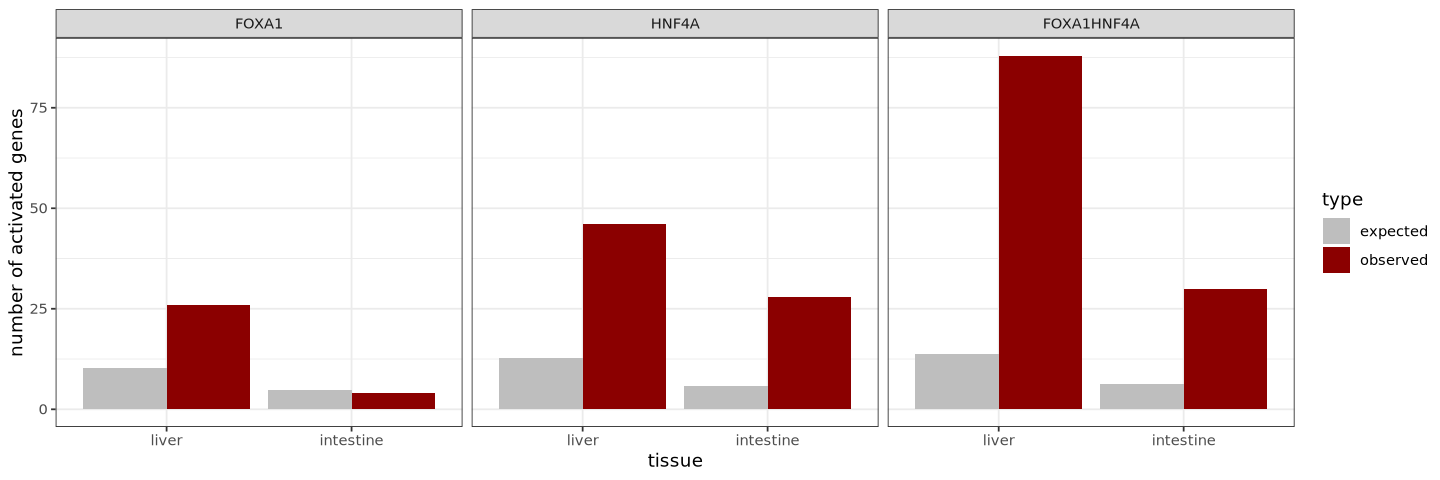

In [58]:
options(repr.plot.width = 12, repr.plot.height = 4)
d <- rbind(
    data.frame(line = enrichment$line, tissue = enrichment$tissue, type = "expected", n = enrichment$expected),
    data.frame(line = enrichment$line, tissue = enrichment$tissue, type = "observed", n = enrichment$observed))
d$tissue <- factor(d$tissue, levels = c("liver", "intestine"))
d$line   <- factor(d$line, levels = c("FOXA1", "HNF4A", "FOXA1HNF4A"))
ggplot(d, aes(x = tissue, y = n, fill = type)) +
    geom_col(position = "dodge") +
    scale_fill_manual(values = c("expected" = "gray", "observed" = "darkred")) +
    facet_wrap(~ line) +
    ylab("number of activated genes") +
    theme_bw()

- FOXA1 alone activates liver genes (26 observed, 10 expected), but no intestinal genes.
- HNF4A alone activates both liver (46 observed, 13 expected) and intestinal genes (28 observed, 6 expected).
- FOXA1-HNF4A activates the most liver genes.

This is in line with Figure 2A and 2B of the paper (FOXA1: 33 liver genes, intestine not significant, HNF4A: 47 liver genes, intestine significant).

**This is not what the pioneer factor hypothesis predicts!** HNF4A, the "non-pioneer" factor, can activate liver genes on its own, even more than FOXA1, the "pioneer" factor.

### Do FOXA1 and HNF4A activate the same liver genes?

Let's compare the activated liver genes between the three lines. An [UpSet plot](https://upset.app/) shows the size of each intersection: a dot means the gene is activated in that line, connected dots mean that the genes are activated in multiple lines.

In [59]:
library(UpSetR)
activated_liver <- lapply(activated, function(x) intersect(x, liver_genes))
sapply(activated_liver, length)

FOXA1      HNF4A FOXA1HNF4A 
        26         46         88

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


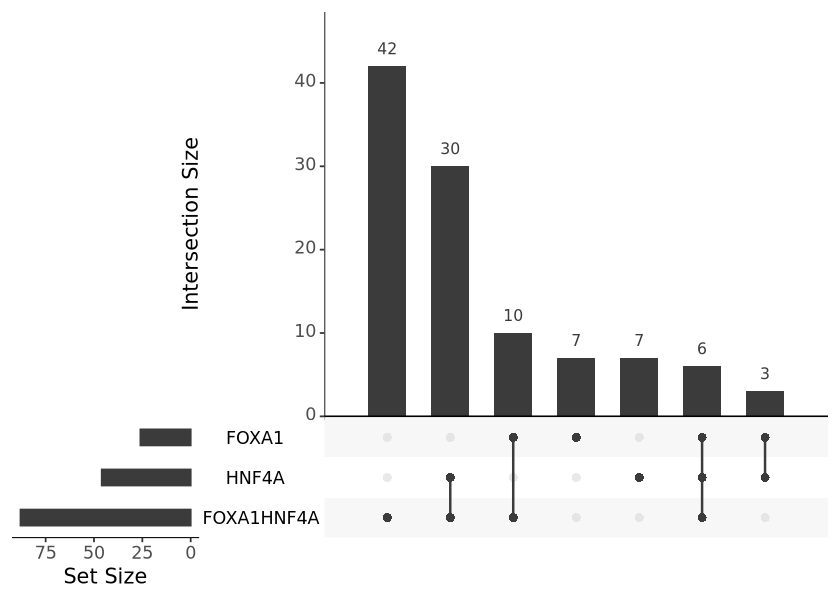

In [60]:
options(repr.plot.width = 7, repr.plot.height = 5)
upset(fromList(activated_liver), order.by = "freq", text.scale = 1.5)

- Only few liver genes are activated by both FOXA1 alone and HNF4A alone (6 + 3 genes): FOXA1 and HNF4A mostly activate *different* liver genes (Figure 2C-D of the paper).
- Most liver genes activated by FOXA1 or HNF4A alone are also activated by FOXA1-HNF4A.
- 42 liver genes are only activated when both factors are expressed together.

Genes that are activated by FOXA1-HNF4A but neither by FOXA1 nor HNF4A alone need *both* factors (Figure 4A of the paper):

In [61]:
need_both <- setdiff(activated_liver$FOXA1HNF4A, union(activated_liver$FOXA1, activated_liver$HNF4A))
length(need_both)
need_both

[1] 42

[1] "HMGCS2"      "CFHR1"       "CFHR2"       "CFHR5"       "PLGLB2"     
 [6] "PROC"        "ITIH3"       "ITIH4"       "SLC2A2"      "AHSG"       
[11] "FETUB"       "BDH1"        "UGT2B10"     "GC"          "AFM"        
[16] "FGA"         "C9"          "PLG"         "EPO"         "AKR1D1"     
[21] "FGL1"        "GLDC"        "ORM1"        "ORM2"        "A1CF"       
[26] "F2"          "SLC22A9"     "CLEC1B"      "GYS2"        "F7"         
[31] "PROZ"        "RNASE4"      "CES1"        "CA5A"        "ASGR2"      
[36] "CYP2A6"      "CYP2A7"      "CYP2B6"      "APOC4-APOC2" "LBP"        
[41] "SERPIND1"    "UPB1"

Let's visualize the expression of all activated liver genes in all samples using a heatmap. We use the variance stabilized counts of all samples (`vsd_all`, computed above).

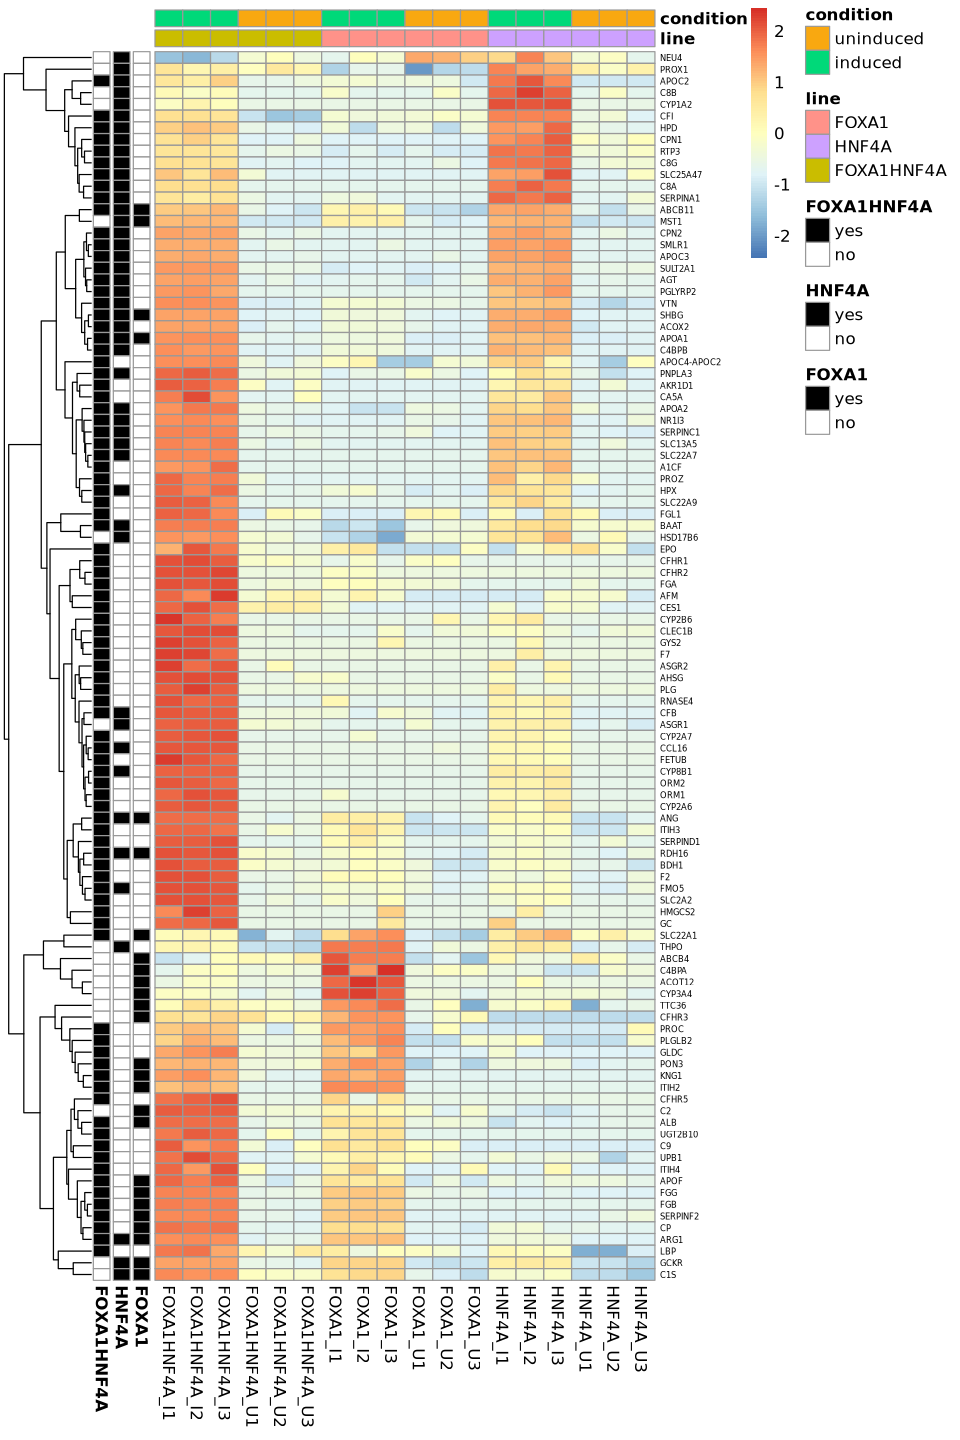

In [62]:
options(repr.plot.width = 8, repr.plot.height = 12)
all_activated_liver <- unique(unlist(activated_liver))
all_activated_liver <- all_activated_liver[all_activated_liver %in% rownames(vsd_all)]
gene_annotation <- data.frame(
    row.names  = all_activated_liver,
    FOXA1      = ifelse(all_activated_liver %in% activated_liver$FOXA1, "yes", "no"),
    HNF4A      = ifelse(all_activated_liver %in% activated_liver$HNF4A, "yes", "no"),
    FOXA1HNF4A = ifelse(all_activated_liver %in% activated_liver$FOXA1HNF4A, "yes", "no"))
ann_colors <- list(FOXA1 = c(yes = "black", no = "white"), HNF4A = c(yes = "black", no = "white"), FOXA1HNF4A = c(yes = "black", no = "white"))
pheatmap(assay(vsd_all)[all_activated_liver, ],
         scale = "row", cluster_cols = FALSE,
         annotation_col = coldata[, c("line", "condition")],
         annotation_row = gene_annotation, annotation_colors = ann_colors,
         fontsize_row = 5)
options(repr.plot.width = 7, repr.plot.height = 5)

The genes cluster in groups:

- genes activated by HNF4A (and FOXA1-HNF4A), for example the apolipoproteins APOA2 and APOC3 and SERPINA1.
- genes activated by FOXA1 (and FOXA1-HNF4A), for example ALB and the fibrinogens FGB and FGG.
- genes activated by both FOXA1 and HNF4A alone, for example APOA1 and ARG1.
- genes that are only activated in the FOXA1-HNF4A line, for example FGA, PLG (plasminogen) and F2 (prothrombin). These genes need both factors.

### What is the function of the activated liver genes? Gene ontology (GO) enrichment

[Gene Ontology](http://geneontology.org/) (GO) is a database that describes the function of genes using a controlled vocabulary of terms. These terms are organized in three categories:

- Biological Process (BP), e.g. "cholesterol metabolic process"
- Molecular Function (MF), e.g. "DNA binding"
- Cellular Component (CC), e.g. "nucleus"

Similar to the liver enrichment above, we can test for each GO term whether it is enriched in a list of genes compared to a universe of genes using a hypergeometric test. This is implemented in the function `enrichGO` of the package [clusterProfiler](https://yulab-smu.top/biomedical-knowledge-mining-book/). Because we test thousands of GO terms, we need to correct for multiple testing.

In the paper (Supplementary files 1 and 2), the liver genes activated by FOXA1 were enriched for fibrinolysis and complement activation, while the liver genes activated by HNF4A were enriched for cholesterol import and lipoprotein remodeling. Let's see if we find the same.

As universe we use all genes that were tested in the corresponding DESeq2 analysis (after filtering).

In [63]:
suppressPackageStartupMessages({
    library(clusterProfiler)
    library(org.Hs.eg.db)
})

In [64]:
run_go <- function(genes, universe) {
    enrichGO(gene          = genes,
             universe      = universe,
             OrgDb         = org.Hs.eg.db,
             keyType       = "SYMBOL",   # our genes are gene symbols (gene names)
             ont           = "BP",       # biological process
             pAdjustMethod = "BH",
             pvalueCutoff  = 0.05,
             qvalueCutoff  = 0.2,
             minGSSize     = 5)
}

In [65]:
go_foxa1 <- run_go(activated_liver$FOXA1, rownames(results_per_line$FOXA1$dds))
head(as.data.frame(go_foxa1)[, c("Description", "GeneRatio", "BgRatio", "p.adjust", "geneID")], 15)

,Description,GeneRatio,BgRatio,p.adjust,geneID
,<chr>,<chr>,<chr>,<dbl>,<chr>
GO:0006959,humoral immune response,7/25,109/11237,2.262587e-06,CFHR3/C4BPA/KNG1/FGB/C2/C1S/ANG
GO:0030195,negative regulation of blood coagulation,4/25,24/11237,5.350582e-05,KNG1/FGB/FGG/SERPINF2
GO:1900047,negative regulation of hemostasis,4/25,24/11237,5.350582e-05,KNG1/FGB/FGG/SERPINF2
GO:0050819,negative regulation of coagulation,4/25,26/11237,5.629028e-05,KNG1/FGB/FGG/SERPINF2
GO:0006956,complement activation,4/25,29/11237,7.122189e-05,CFHR3/C4BPA/C2/C1S
GO:0061045,negative regulation of wound healing,4/25,34/11237,1.150251e-04,KNG1/FGB/FGG/SERPINF2
GO:0030193,regulation of blood coagulation,4/25,37/11237,1.364911e-04,KNG1/FGB/FGG/SERPINF2
GO:1900046,regulation of hemostasis,4/25,38/11237,1.364911e-04,KNG1/FGB/FGG/SERPINF2
GO:0050818,regulation of coagulation,4/25,42/11237,1.828742e-04,KNG1/FGB/FGG/SERPINF2


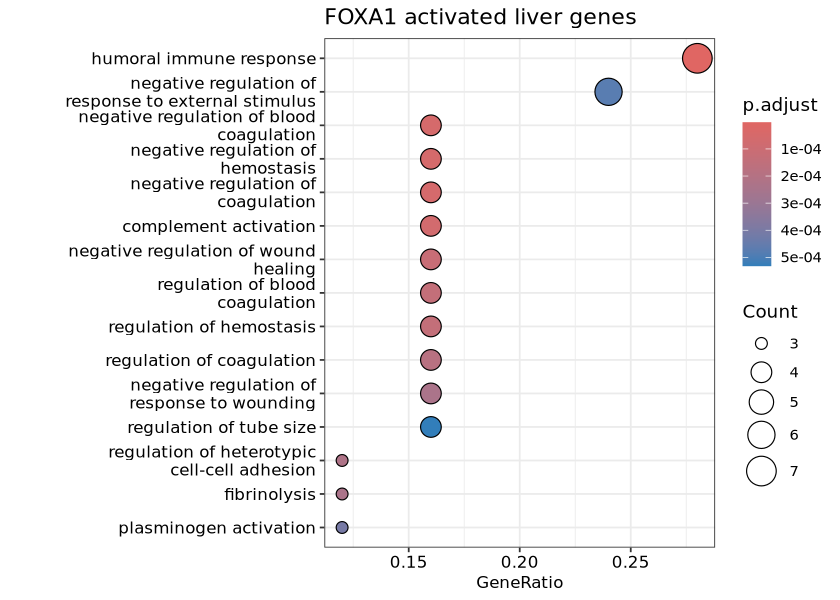

In [66]:
dotplot(go_foxa1, showCategory = 15, font.size = 10) + theme(plot.margin = margin(5, 5, 5, 60)) + ggtitle("FOXA1 activated liver genes")

In [67]:
go_hnf4a <- run_go(activated_liver$HNF4A, rownames(results_per_line$HNF4A$dds))
head(as.data.frame(go_hnf4a)[, c("Description", "GeneRatio", "BgRatio", "p.adjust", "geneID")], 15)

,Description,GeneRatio,BgRatio,p.adjust,geneID
,<chr>,<chr>,<chr>,<dbl>,<chr>
GO:0006959,humoral immune response,10/44,105/11413,4.757871e-09,C8A/C8B/C4BPB/CFI/CFB/C8G/HPX/C1S/ANG/CCL16
GO:0002455,humoral immune response mediated by circulating immunoglobulin,7/44,29/11413,4.757871e-09,C8A/C8B/C4BPB/CFI/C8G/HPX/C1S
GO:0008202,steroid metabolic process,12/44,207/11413,4.757871e-09,FMO5/APOA2/PROX1/ABCB11/CYP8B1/ACOX2/BAAT/APOA1/HSD17B6/RDH16/CYP1A2/SULT2A1
GO:0006956,complement activation,7/44,30/11413,4.757871e-09,C8A/C8B/C4BPB/CFI/CFB/C8G/C1S
GO:0006958,"complement activation, classical pathway",6/44,22/11413,4.270714e-08,C8A/C8B/C4BPB/CFI/C8G/C1S
GO:0008206,bile acid metabolic process,6/44,34/11413,6.198526e-07,PROX1/ABCB11/CYP8B1/ACOX2/BAAT/SULT2A1
GO:1901615,organic hydroxy compound metabolic process,12/44,347/11413,8.429587e-07,FMO5/APOA2/PROX1/ABCB11/CYP8B1/ACOX2/BAAT/APOA1/HSD17B6/RDH16/CYP1A2/SULT2A1
GO:0034368,protein-lipid complex remodeling,5/44,21/11413,1.572849e-06,APOA2/AGT/APOC3/APOA1/APOC2
GO:0034369,plasma lipoprotein particle remodeling,5/44,21/11413,1.572849e-06,APOA2/AGT/APOC3/APOA1/APOC2


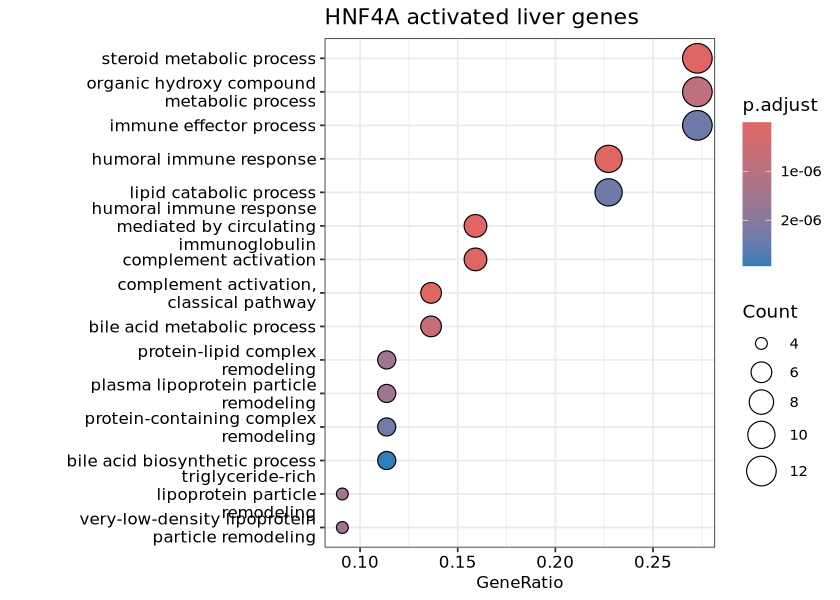

In [68]:
dotplot(go_hnf4a, showCategory = 15, font.size = 10) + theme(plot.margin = margin(5, 5, 5, 60)) + ggtitle("HNF4A activated liver genes")

As in the paper:

- the liver genes activated by FOXA1 are enriched for terms related to blood coagulation, **fibrinolysis** (the breakdown of blood clots, e.g. KNG1, FGB, FGG, SERPINF2) and **complement activation** (part of the innate immune system).
- the liver genes activated by HNF4A are enriched for terms related to lipid metabolism, **(plasma) lipoprotein particle remodeling** (e.g. the apolipoproteins) and bile acid metabolism, but also complement activation.

So FOXA1 and HNF4A each activate a different part of the liver gene expression program.

We can also look at all activated genes (not only the liver genes) of the FOXA1-HNF4A line.

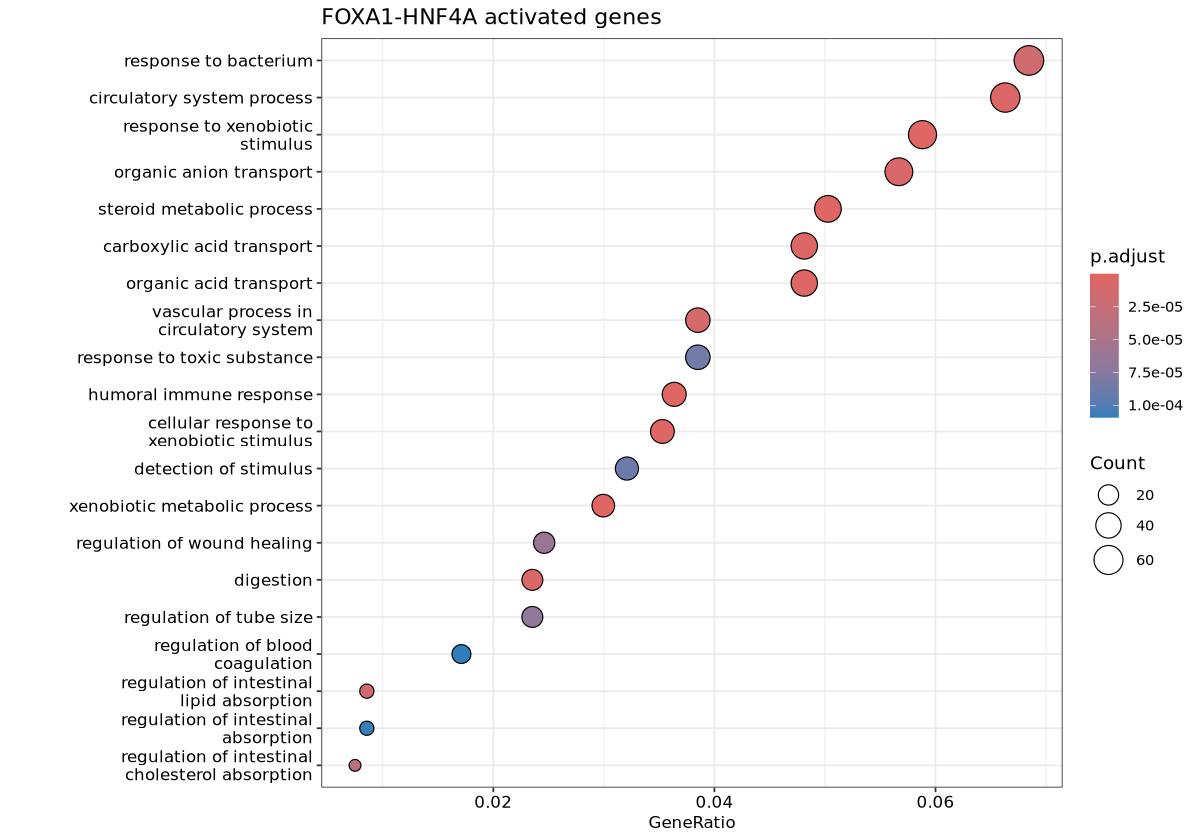

In [69]:
go_fh <- run_go(activated$FOXA1HNF4A, rownames(dds))
options(repr.plot.width = 10, repr.plot.height = 7)
dotplot(go_fh, showCategory = 20, font.size = 10) + theme(plot.margin = margin(5, 5, 5, 60)) + ggtitle("FOXA1-HNF4A activated genes")

The activated genes are enriched for typical liver (and intestine) functions: transport of organic acids, steroid metabolism, response to xenobiotics (detoxification of drugs and toxins), blood coagulation, digestion and intestinal lipid absorption.

### Comparison with the paper

| | this notebook | paper |
|---|---|---|
| FOXA1-HNF4A: activated liver genes (expected) | 88 (14) | 91 (18) |
| FOXA1-HNF4A: activated intestine genes (expected) | 30 (6) | 38 (9) |
| FOXA1: activated liver genes | 26 | 33 |
| FOXA1: intestine enrichment | not significant | not significant |
| HNF4A: activated liver genes | 46 | 47 |
| HNF4A: intestine enrichment | significant | significant |
| liver genes only activated by FOXA1-HNF4A | 42 | 31 |
| GO FOXA1 liver genes | fibrinolysis, complement activation | fibrinolysis, complement activation |
| GO HNF4A liver genes | lipoprotein particle remodeling | cholesterol import, lipoprotein remodeling |

Our numbers are not exactly the same as in the paper. This is expected, because:

- we used a different pipeline (STAR + featureCounts instead of Salmon), and a different version of the genome annotation.
- we required a padj < 0.05, the paper only used a log2 fold change threshold.
- we used shrunken log2 fold changes.
- we used a newer version of the Human Protein Atlas.
- the universe used for the hypergeometric test is not described in the paper.

Nevertheless, the conclusions are the same!

## Conclusion

1. Expression of FOXA1 and HNF4A in K562 cells (a blood cell line) activates more than 2000 genes, among which many liver and intestine specific genes.
2. Both FOXA1 alone and HNF4A alone can activate liver genes. HNF4A alone also activates intestinal genes.
3. FOXA1 and HNF4A activate largely different sets of liver genes, and a subset of liver genes requires both factors.

According to the pioneer factor hypothesis only the pioneer factor FOXA1 should be able to activate silent genes on its own. The RNA-seq data shows that the "non-pioneer" factor HNF4A can do so as well. Using ATAC-seq and CUT&Tag data (not analysed here), the authors show that both factors can bind to and open closed chromatin. They conclude that "pioneer activity" is not a property of a special class of transcription factors, but depends on the binding affinity of the transcription factor and the genomic context.

## Exercises

1. Change the threshold for "activated" genes (e.g. `max_uninduced = 10` or `log2FC_thr = 2`). How does this change the number of activated liver genes and the enrichment?
2. Repeat the hypergeometric test for other tissues in the HPA (e.g. `"brain"`, `"bone marrow"`, `"pancreas"`). Are these tissues also enriched? What do you expect?
3. Which genes are *downregulated* upon FOXA1-HNF4A induction? Run a GO enrichment on these genes. Do you see a decrease in blood cell related genes?
4. Instead of analysing each line separately, make a single DESeqDataSet with all 18 samples and design `~ group` and use `results(dds_all, contrast = c("group", "FOXA1_induced", "FOXA1_uninduced"))`. Do you get the same results? (Hint: what is the difference in how the dispersion is estimated?)
5. Plot the normalized counts of the genes `ALB`, `APOA2` and `AMDHD1` across all 18 samples. Which factor(s) activate these genes?